In [99]:
import numpy as np
import os
import statistics

In [100]:
T = 5
n_trayectories = 1000 #ESTO CAMBIARÁ
n_times = 21
n_times_1 = 6
n_times_2 = (n_times - n_times_1)
S_0 = [1,1,1] #ESTO CAMBIARÁ
mu = np.array([0.01, 0.01, 0.01])
sigma = np.array([0.2, 0.25, 0.3]) #ESTO CAMBIARÁ
rho = np.array([[1.00, 0.60, 0.30], [0.60, 1.00, 0.40], [0.30, 0.40, 1.00]]) #ESTO CAMBIARÁ
seed = 42

In [101]:
A = np.linalg.cholesky(rho)
At = A.T
rng = np.random.default_rng(seed = seed)
X1 = rng.standard_normal((1, n_times_1-1, (len(S_0))))
X1_cor = X1 @ At
X2 = rng.standard_normal((n_trayectories, n_times_2, len(S_0)))
X2_cor = X2 @ At

In [102]:
S1 = np.empty((n_trayectories, n_times_1, len(S_0)))
S1[:, 0, :] = np.array(S_0)
delta_t = T/(n_times - 1)
S1[:, 1:, :] = np.exp(((mu-(sigma**2/2))*delta_t)+(sigma*np.sqrt(delta_t)*X1_cor))

In [103]:
S2 = np.empty((n_trayectories, n_times, len(S_0)))
S2[:, :n_times_1, :] = S1
S2[:, n_times_1: , :] = np.exp(((mu-(sigma**2/2))*delta_t)+(sigma*np.sqrt(delta_t)*X2_cor))

In [104]:
MC = np.cumprod(S2, axis = 1)

In [105]:
import matplotlib.pyplot as plt

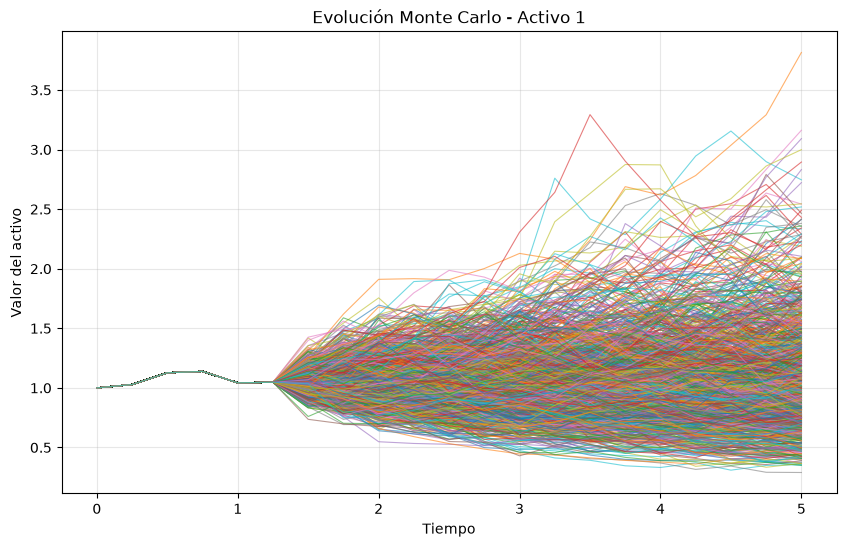

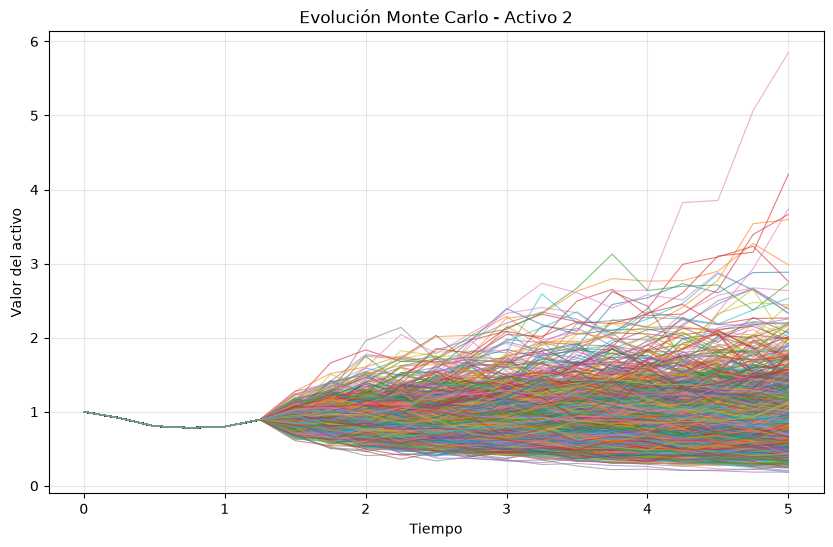

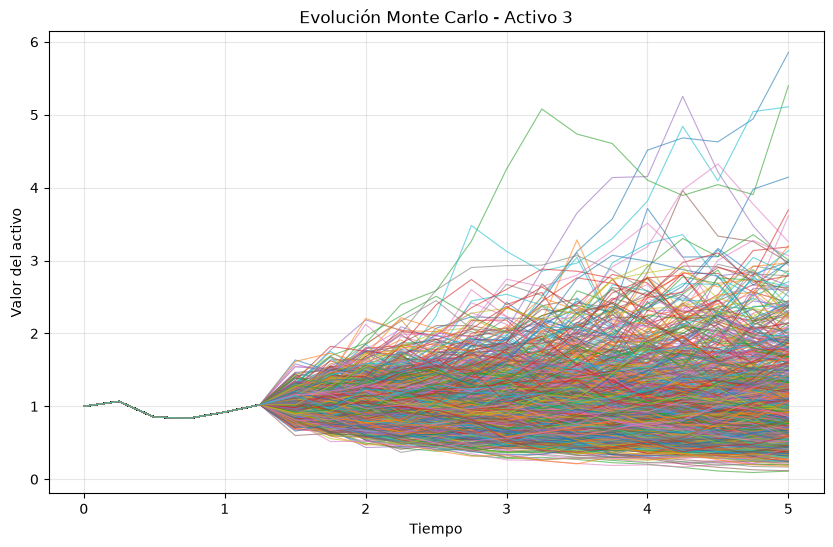

In [106]:
tiempo = np.linspace(0, T, n_times)
for activo in range(len(S_0)):
    plt.figure(figsize=(10, 6))
    for trayectoria in range(n_trayectories):
        plt.plot(
            tiempo,
            MC[trayectoria, :, activo],
            alpha=0.6,
            linewidth=0.8
        )
    plt.title(f"Evolución Monte Carlo - Activo {activo + 1}")
    plt.xlabel("Tiempo")
    plt.ylabel("Valor del activo")
    plt.grid(alpha=0.3)
    plt.show()